In [1]:
import pandas as pd

caminho_2025 = '../DATA/RAW/EAR_DIARIO_SUBSISTEMA_2025.csv'

df_2025 = pd.read_csv(caminho_2025, sep=';')

df_2025.head()

,id_subsistema,nom_subsistema,ear_data,ear_max_subsistema,ear_verif_subsistema_mwmes,ear_verif_subsistema_percentual
0,NE,NORDESTE,2025-01-01,51691.226,25936.409,50.1757
1,N,NORTE,2025-01-01,15302.396,8257.997,53.9654
2,SE,SUDESTE,2025-01-01,204615.328,105698.119,51.6570
3,S,SUL,2025-01-01,20459.242,16238.291,79.3690
4,NE,NORDESTE,2025-01-02,51691.226,26172.624,50.6326


In [2]:
# Definindo o caminho do arquivo de 2026
caminho_2026 = '../DATA/RAW/EAR_DIARIO_SUBSISTEMA_2026.csv'

# Lendo o arquivo de 2026 com as configurações corretas
df_2026 = pd.read_csv(caminho_2026, sep=';', encoding='utf-8')

# Visualizando as 5 primeiras linhas do arquivo de 2026
df_2026.head()

,id_subsistema,nom_subsistema,ear_data,ear_max_subsistema,ear_verif_subsistema_mwmes,ear_verif_subsistema_percentual
0,NE,NORDESTE,2026-01-01,51616.053,23936.509,46.3742
1,N,NORTE,2026-01-01,15596.595,8530.426,54.6942
2,SE,SUDESTE,2026-01-01,200339.189,84689.427,42.2730
3,S,SUL,2026-01-01,19907.678,14307.358,71.8685
4,NE,NORDESTE,2026-01-02,51616.053,23977.396,46.4534


In [3]:
df_2026.info()


<class 'pandas.DataFrame'>
RangeIndex: 1264 entries, 0 to 1263
Data columns (total 6 columns):
 #   Column                           Non-Null Count  Dtype  
---  ------                           --------------  -----  
 0   id_subsistema                    1264 non-null   str    
 1   nom_subsistema                   1264 non-null   str    
 2   ear_data                         1264 non-null   str    
 3   ear_max_subsistema               1264 non-null   float64
 4   ear_verif_subsistema_mwmes       1264 non-null   float64
 5   ear_verif_subsistema_percentual  1264 non-null   float64
dtypes: float64(3), str(3)
memory usage: 59.4 KB


In [4]:
# Empilhando os dois DataFrames em uma única tabela

df_completo = pd.concat([df_2025, df_2026], ignore_index=True)

# Verificando o tamanho da nova tabela unificada
print("Tamanho da tabela completa:", df_completo.shape)

# Mostrando as últimas 5 linhas para garantir que o final do arquivo de 2026 foi incorporado
df_completo.tail()

Tamanho da tabela completa: (2724, 6)


,id_subsistema,nom_subsistema,ear_data,ear_max_subsistema,ear_verif_subsistema_mwmes,ear_verif_subsistema_percentual
2719,S,SUL,2026-11-11,19907.678,16460.051,82.6819
2720,NE,NORDESTE,2026-11-12,51616.053,30917.049,59.8981
2721,N,NORTE,2026-11-12,15596.595,8763.291,56.1872
2722,SE,SUDESTE,2026-11-12,200339.189,110390.310,55.1017
2723,S,SUL,2026-11-12,19907.678,16310.930,81.9329


In [5]:
# Convertendo a coluna 'ear_data' de texto para o formato de data real do Pandas
df_completo['ear_data'] = pd.to_datetime(df_completo['ear_data'])

# Verificando se a conversão funcionou olhando os tipos de dados novamente
df_completo.info()


<class 'pandas.DataFrame'>
RangeIndex: 2724 entries, 0 to 2723
Data columns (total 6 columns):
 #   Column                           Non-Null Count  Dtype         
---  ------                           --------------  -----         
 0   id_subsistema                    2724 non-null   str           
 1   nom_subsistema                   2724 non-null   str           
 2   ear_data                         2724 non-null   datetime64[us]
 3   ear_max_subsistema               2724 non-null   float64       
 4   ear_verif_subsistema_mwmes       2724 non-null   float64       
 5   ear_verif_subsistema_percentual  2724 non-null   float64       
dtypes: datetime64[us](1), float64(3), str(2)
memory usage: 127.8 KB


In [6]:
# Criando a coluna 'ano' extraindo apenas o ano da data
df_completo['ano'] = df_completo['ear_data'].dt.year

# Criando a coluna 'mes' extraindo apenas o número do mês da data
df_completo['mes'] = df_completo['ear_data'].dt.month

# Visualizando a tabela para conferir as novas colunas
df_completo.head()

,id_subsistema,nom_subsistema,ear_data,ear_max_subsistema,ear_verif_subsistema_mwmes,ear_verif_subsistema_percentual,ano,mes
0,NE,NORDESTE,2025-01-01,51691.226,25936.409,50.1757,2025,1
1,N,NORTE,2025-01-01,15302.396,8257.997,53.9654,2025,1
2,SE,SUDESTE,2025-01-01,204615.328,105698.119,51.6570,2025,1
3,S,SUL,2025-01-01,20459.242,16238.291,79.3690,2025,1
4,NE,NORDESTE,2025-01-02,51691.226,26172.624,50.6326,2025,1


In [7]:
# Agrupando os dados por subsistema, ano e mês
# Calculando a média apenas da coluna percentual
media_mensal = df_completo.groupby(['nom_subsistema', 'ano', 'mes'])['ear_verif_subsistema_percentual'].mean().reset_index()

# Arredondando os valores para 2 casas decimais para ficar mais limpo
media_mensal['ear_verif_subsistema_percentual'] = media_mensal['ear_verif_subsistema_percentual'].round(2)

# Visualizando as primeiras linhas do resultado
media_mensal.head(10)

,nom_subsistema,ano,mes,ear_verif_subsistema_percentual
0,NORDESTE,2025,1,59.66
1,NORDESTE,2025,2,77.09
2,NORDESTE,2025,3,78.82
3,NORDESTE,2025,4,77.00
4,NORDESTE,2025,5,75.39
5,NORDESTE,2025,6,71.22
6,NORDESTE,2025,7,66.90
7,NORDESTE,2025,8,62.27
8,NORDESTE,2025,9,56.82
9,NORDESTE,2025,10,51.48


In [8]:
# Criando uma tabela onde os anos viram colunas
comparativo_mensal = media_mensal.pivot_table(
    index=['nom_subsistema', 'mes'],  # O que fica nas linhas (Subsistema e Mês)
    columns='ano',                    # O que vira coluna (2025 e 2026)
    values='ear_verif_subsistema_percentual' # Os valores que vão preencher a tabela
).reset_index()

# Arredondando novamente para garantir que fique bonito
comparativo_mensal = comparativo_mensal.round(2)

# Mostrando a tabela comparativa
comparativo_mensal

ano,nom_subsistema,mes,2025,2026
0,NORDESTE,1,59.66,48.90
1,NORDESTE,2,77.09,62.63
2,NORDESTE,3,78.82,83.03
3,NORDESTE,4,77.00,94.50
4,NORDESTE,5,75.39,95.00
5,NORDESTE,6,71.22,91.59
6,NORDESTE,7,66.90,87.20
7,NORDESTE,8,62.27,80.30
8,NORDESTE,9,56.82,72.36
9,NORDESTE,10,51.48,64.95


In [9]:
# Calculando a diferença absoluta (2026 - 2025)
comparativo_mensal['dif_absoluta'] = comparativo_mensal[2026] - comparativo_mensal[2025]

# Calculando a variação percentual em relação a 2025
# (diferença / valor de 2025) * 100
comparativo_mensal['var_percentual'] = (comparativo_mensal['dif_absoluta'] / comparativo_mensal[2025]) * 100

# Arredondando para ficar legível
comparativo_mensal = comparativo_mensal.round(2)

# Filtrando apenas o NORDESTE para ver o seu insight validado
comparativo_mensal[comparativo_mensal['nom_subsistema'] == 'NORDESTE'].head(12)

ano,nom_subsistema,mes,2025,2026,dif_absoluta,var_percentual
0,NORDESTE,1,59.66,48.90,-10.76,-18.04
1,NORDESTE,2,77.09,62.63,-14.46,-18.76
2,NORDESTE,3,78.82,83.03,4.21,5.34
3,NORDESTE,4,77.00,94.50,17.50,22.73
4,NORDESTE,5,75.39,95.00,19.61,26.01
5,NORDESTE,6,71.22,91.59,20.37,28.60
6,NORDESTE,7,66.90,87.20,20.30,30.34
7,NORDESTE,8,62.27,80.30,18.03,28.95
8,NORDESTE,9,56.82,72.36,15.54,27.35
9,NORDESTE,10,51.48,64.95,13.47,26.17


In [10]:
# Agrupando por subsistema e calculando a média da variação percentual
resumo_por_subsistema = comparativo_mensal.groupby('nom_subsistema')[['dif_absoluta', 'var_percentual']].mean().reset_index()

# Arredondando para 2 casas decimais
resumo_por_subsistema = resumo_por_subsistema.round(2)

# Ordenando do maior impacto para o menor
resumo_por_subsistema = resumo_por_subsistema.sort_values(by='var_percentual', ascending=False)

# Exibindo o resultado
resumo_por_subsistema

ano,nom_subsistema,dif_absoluta,var_percentual
0,NORDESTE,10.74,17.23
2,SUDESTE,-1.70,-1.29
3,SUL,-4.66,-5.67
1,NORTE,-7.50,-9.04


###  Insights Preliminares: Comparativo 2025 vs 2026

A análise da variação média do armazenamento (EAR) revela um impacto heterogêneo do clima sobre os subsistemas:

*   **Nordeste (+17,23%):** Apresentou o maior crescimento relativo. Apesar de um início de ano desfavorável, a recuperação ao longo de 2026 foi expressiva, superando em muito os níveis de 2025.
*   **Sudeste (-1,29%):** Manteve-se praticamente estável, indicando que o comportamento hidrológico nesta região foi similar entre os dois anos analisados.
*   **Sul (-5,67%):** Registrou uma retração moderada no armazenamento médio.
*   **Norte (-9,04%):** Foi o subsistema com a maior queda relativa, sinalizando uma condição hidrológica mais seca em 2026 se comparada ao ano anterior.

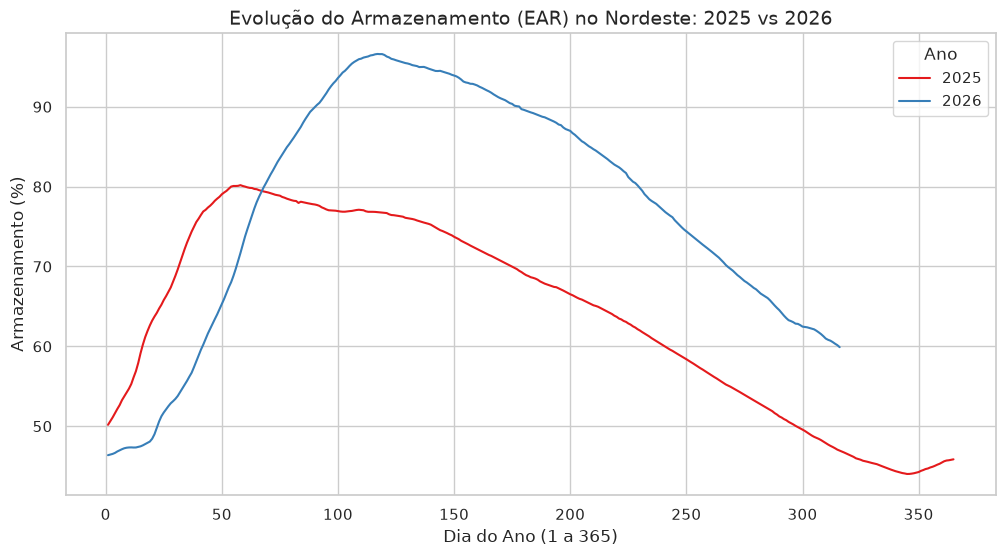

In [11]:
import matplotlib.pyplot as plt
import seaborn as sns

# Configurando o estilo visual do gráfico
sns.set_theme(style="whitegrid")
plt.figure(figsize=(12, 6))

# Criando uma coluna com o dia do ano para sobrepor os gráficos
df_completo['dia_do_ano'] = df_completo['ear_data'].dt.day_of_year

# Filtrando apenas os dados do NORDESTE
dados_ne = df_completo[df_completo['nom_subsistema'] == 'NORDESTE']

# Plotando o gráfico de linhas
sns.lineplot(data=dados_ne, x='dia_do_ano', y='ear_verif_subsistema_percentual', hue='ano', palette='Set1')

# Adicionando títulos e rótulos
plt.title('Evolução do Armazenamento (EAR) no Nordeste: 2025 vs 2026', fontsize=14)
plt.xlabel('Dia do Ano (1 a 365)', fontsize=12)
plt.ylabel('Armazenamento (%)', fontsize=12)

# Ajustando a legenda
plt.legend(title='Ano')

# Exibindo o gráfico
plt.show()

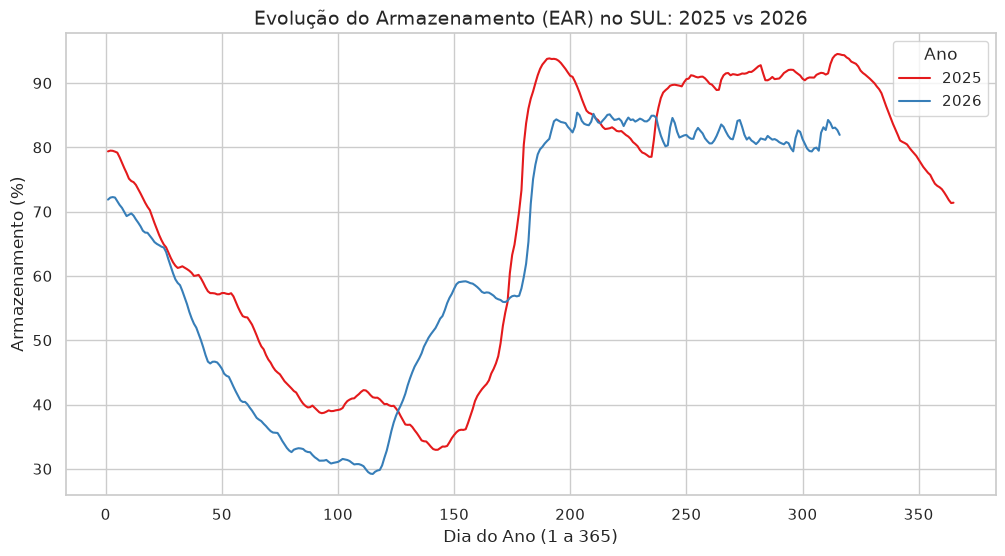

In [12]:
# Configurando o estilo visual do gráfico
sns.set_theme(style="whitegrid")
plt.figure(figsize=(12, 6))

# Criando uma coluna com o dia do ano para sobrepor os gráficos
df_completo['dia_do_ano'] = df_completo['ear_data'].dt.day_of_year

# Filtrando apenas os dados do SUL
dados_ne = df_completo[df_completo['nom_subsistema'] == 'SUL']

# Plotando o gráfico de linhas
sns.lineplot(data=dados_ne, x='dia_do_ano', y='ear_verif_subsistema_percentual', hue='ano', palette='Set1')

# Adicionando títulos e rótulos
plt.title('Evolução do Armazenamento (EAR) no SUL: 2025 vs 2026', fontsize=14)
plt.xlabel('Dia do Ano (1 a 365)', fontsize=12)
plt.ylabel('Armazenamento (%)', fontsize=12)

# Ajustando a legenda
plt.legend(title='Ano')

# Exibindo o gráfico
plt.show()

In [13]:
# Corrigindo o aviso de depreciação do Pandas
df_completo['dia_do_ano'] = df_completo['ear_data'].dt.day_of_year

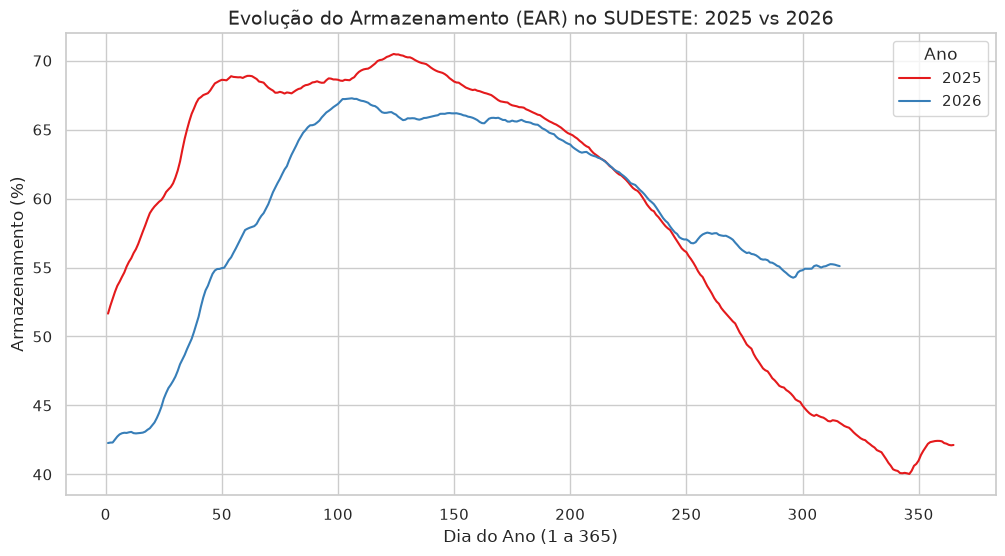

In [14]:
# Configurando o estilo visual do gráfico
sns.set_theme(style="whitegrid")
plt.figure(figsize=(12, 6))

# Criando uma coluna com o dia do ano para sobrepor os gráficos
df_completo['dia_do_ano'] = df_completo['ear_data'].dt.day_of_year

# Filtrando apenas os dados do SUL
dados_se = df_completo[df_completo['nom_subsistema'] == 'SUDESTE']

# Plotando o gráfico de linhas
sns.lineplot(data=dados_se, x='dia_do_ano', y='ear_verif_subsistema_percentual', hue='ano', palette='Set1')

# Adicionando títulos e rótulos
plt.title('Evolução do Armazenamento (EAR) no SUDESTE: 2025 vs 2026', fontsize=14)
plt.xlabel('Dia do Ano (1 a 365)', fontsize=12)
plt.ylabel('Armazenamento (%)', fontsize=12)

# Ajustando a legenda
plt.legend(title='Ano')

# Exibindo o gráfico
plt.show()

# Análise de Risco Hídrico e El Niño (2025-2026)
**Objetivo:** Avaliar o impacto do fenômeno El Niño nos níveis de Energia Armazenada (EAR) do ONS, comparando os anos de 2025 e 2026.

**Fonte dos dados:** Dados Abertos do ONS (Operador Nacional do Sistema Elétrico).

**Metodologia:** 
- Extração e limpeza dos dados diários de EAR por subsistema.
- Tratamento de datas e agrupamento mensal.
- Cálculo de variação absoluta e percentual entre os anos.
- Visualização temporal para identificação de anomalias climáticas.

In [15]:
# Gerando o resumo estatístico descritivo da coluna percentual
df_completo['ear_verif_subsistema_percentual'].describe()

count    2724.000000
mean       69.423839
std        17.687374
min        29.199100
25%        56.398150
50%        67.930350
75%        84.302825
max        98.353800
Name: ear_verif_subsistema_percentual, dtype: float64

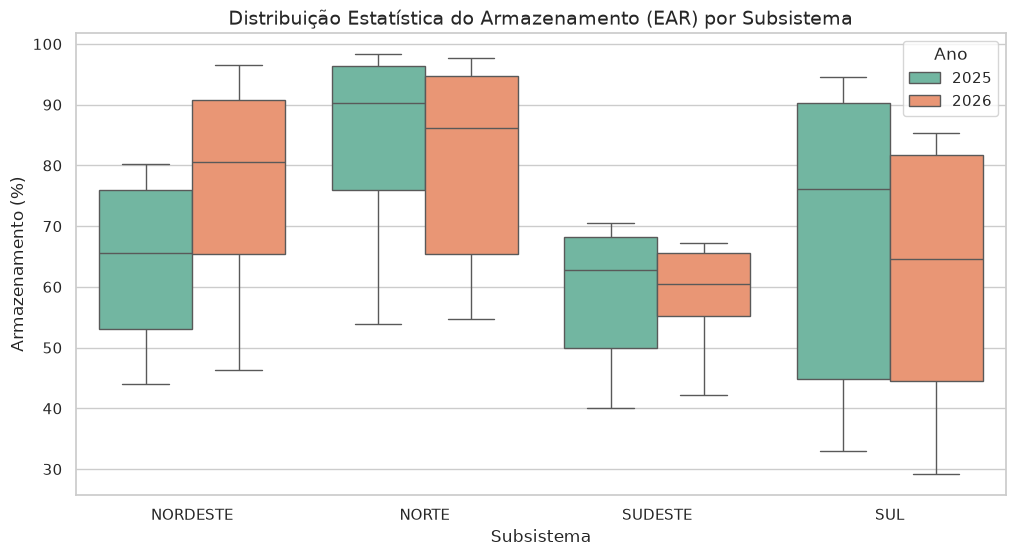

In [16]:
# Criando um Boxplot da distribuição de EAR por subsistema e por ano
plt.figure(figsize=(12, 6))
sns.boxplot(data=df_completo, x='nom_subsistema', y='ear_verif_subsistema_percentual', hue='ano', palette='Set2')

plt.title('Distribuição Estatística do Armazenamento (EAR) por Subsistema', fontsize=14)
plt.xlabel('Subsistema', fontsize=12)
plt.ylabel('Armazenamento (%)', fontsize=12)
plt.legend(title='Ano')
plt.show()

In [18]:
# 1. Criar a coluna 'dia_do_ano' no dataframe original (se ainda não existir)
df_completo['dia_do_ano'] = df_completo['ear_data'].dt.day_of_year

# 2. Criar a tabela diária agrupando por subsistema e pelo dia do ano (1 a 365)
tabela_diaria = df_completo.pivot_table(
    index=['nom_subsistema', 'dia_do_ano'], 
    columns='ano', 
    values='ear_verif_subsistema_percentual'
).reset_index()

# 3. Criar a nossa Feature (delta)
tabela_diaria['delta_diario'] = tabela_diaria[2026] - tabela_diaria[2025]

# 4. Limpar nulos (o final de 2026 tem menos dias que 2025)
tabela_diaria = tabela_diaria.dropna()

# Visualizando as primeiras linhas
tabela_diaria.head()

ano,nom_subsistema,dia_do_ano,2025,2026,delta_diario
0,NORDESTE,1,50.1757,46.3742,-3.8015
1,NORDESTE,2,50.6326,46.4534,-4.1792
2,NORDESTE,3,51.1088,46.5345,-4.5743
3,NORDESTE,4,51.6341,46.6591,-4.9750
4,NORDESTE,5,52.1592,46.8398,-5.3194


In [20]:
from scipy import stats

# 1. Filtrar os dados do Nordeste e do Sudeste
delta_ne = tabela_diaria[tabela_diaria['nom_subsistema'] == 'NORDESTE']['delta_diario']
delta_se = tabela_diaria[tabela_diaria['nom_subsistema'] == 'SUDESTE']['delta_diario']

# 2. Aplicar o Teste T para o Nordeste
# H0 (Hipótese Nula): A média do delta é igual a zero.
# H1 (Hipótese Alternativa): A média do delta é diferente de zero.
t_stat_ne, p_valor_ne = stats.ttest_1samp(delta_ne, 0)
print(f"NORDESTE -> Estatística T: {t_stat_ne:.2f} | P-valor: {p_valor_ne:.4f}")

# 3. Aplicar o Teste T para o Sudeste
t_stat_se, p_valor_se = stats.ttest_1samp(delta_se, 0)
print(f"SUDESTE -> Estatística T: {t_stat_se:.2f} | P-valor: {p_valor_se:.4f}")

NORDESTE -> Estatística T: 15.45 | P-valor: 0.0000
SUDESTE -> Estatística T: -6.11 | P-valor: 0.0000


### Validação Estatística: O impacto do El Niño é real?

Para garantir que as diferenças observadas nos reservatórios entre 2025 e 2026 não são apenas "ruído" ou coincidência do dia a dia, colocamos os dados à prova usando o **Teste T de Student** (com nível de confiança de 95%, ou $\alpha = 0,05$).

Os resultados confirmam que o comportamento climático atual deixou uma marca clara nos dados:

* **Nordeste ($p < 0,0001$):** Não é acaso. O teste confirma que o ganho no volume armazenado em 2026 representa uma mudança estrutural real frente ao ano anterior.
* **Sudeste/Centro-Oeste ($p < 0,0001$):** Mesmo sendo uma oscilação mais discreta nos números, ela é estatisticamente consistente. Isso valida que existe, de fato, uma pressão de queda nos reservatórios da região neste ciclo.